## Линейная регрессия

### Данные

**QSAR fish toxicity** (UCI Machine Learning Repository): 908 химических соединений.
Для каждого измерена острая токсичность для рыбы *Pimephales promelas* (толстоголовый гольян).

| Переменная | Смысл |
|---|---|
| `CIC0` | информационный индекс молекулы (complementary information content, порядок 0) |
| `SM1_Dz` | спектральный момент матрицы расстояний, взвешенной по атомному номеру |
| `GATS1i` | автокорреляция Гири (лаг 1), взвешенная по потенциалу ионизации |
| `NdsCH` | число атомов углерода типа =CH− |
| `NdssC` | число атомов углерода типа =C< |
| `MLOGP` | липофильность (logP по Моригучи) |
| **`LC50`** | **отклик:** $-\log_{10}$ (моль/л) концентрации, при которой за 96 ч гибнет 50% рыб. Больше значение — токсичнее вещество |

QSAR-модели токсичности классически строятся
как линейные зависимости от дескрипторов. В частности, «базовая» (наркотическая)
токсичность почти линейно растёт с липофильностью logP.

In [3]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm, chi2
from sklearn.covariance import MinCovDet
from sklearn.model_selection import KFold

In [4]:
columns = ['CIC0', 'SM1_Dz', 'GATS1i', 'NdsCH', 'NdssC', 'MLOGP', 'LC50']
df = pd.read_csv('qsar_fish_toxicity.csv', sep=';', header=None, names=columns)
features = columns[:-1]
target = 'LC50'

print('Размер:', df.shape)
display(df.head())
display(df.describe().T.round(3))

Размер: (908, 7)


,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
0,3.260,0.829,1.676,0,1,1.453,3.770
1,2.189,0.580,0.863,0,0,1.348,3.115
2,2.125,0.638,0.831,0,0,1.348,3.531
3,3.027,0.331,1.472,1,0,1.807,3.510
4,2.094,0.827,0.860,0,0,1.886,5.390


,count,mean,std,min,25%,50%,75%,max
CIC0,908.0,2.898,0.756,0.667,2.347,2.934,3.407,5.926
SM1_Dz,908.0,0.628,0.428,0.000,0.223,0.570,0.893,2.171
GATS1i,908.0,1.294,0.394,0.396,0.951,1.240,1.562,2.920
NdsCH,908.0,0.229,0.605,0.000,0.000,0.000,0.000,4.000
NdssC,908.0,0.486,0.861,0.000,0.000,0.000,1.000,6.000
MLOGP,908.0,2.109,1.433,-2.884,1.209,2.127,3.105,6.515
LC50,908.0,4.064,1.456,0.053,3.152,3.988,4.908,9.612


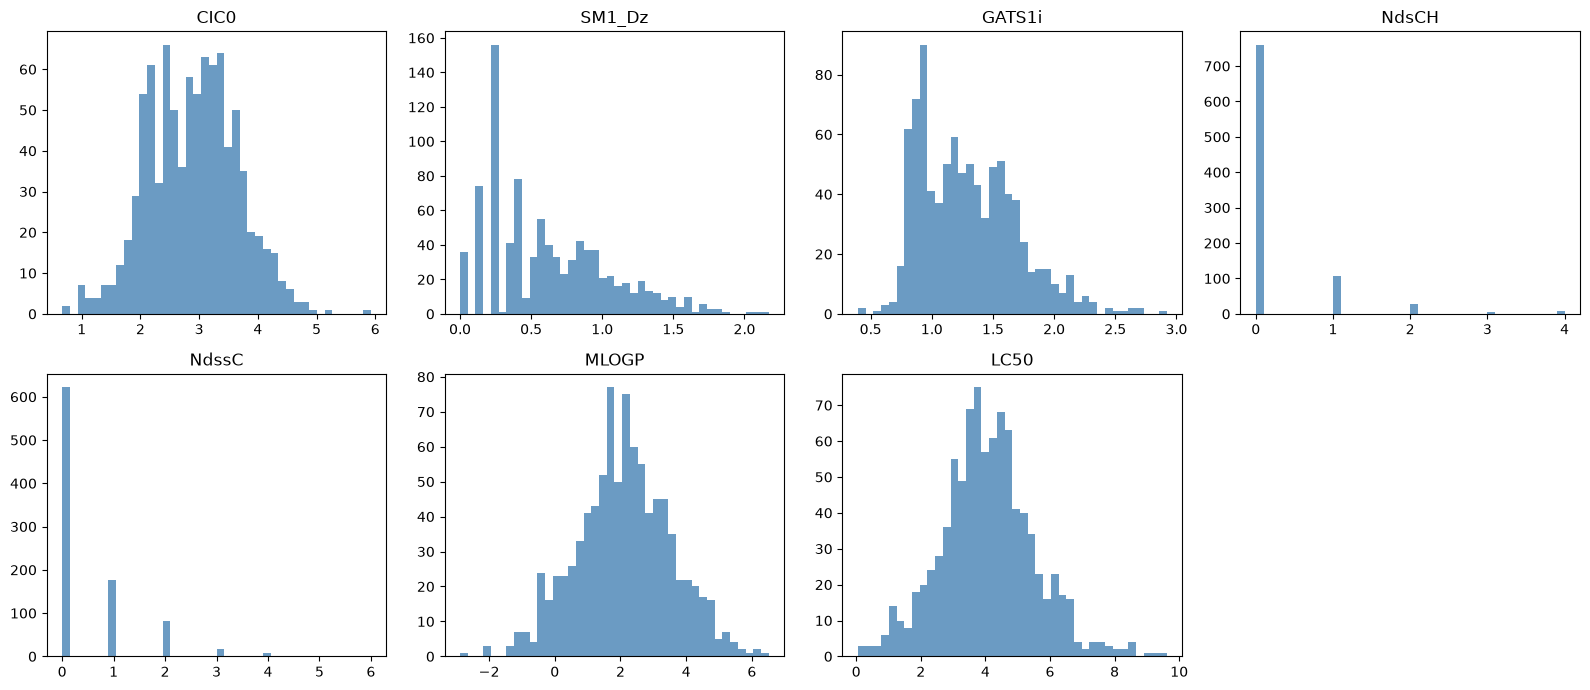

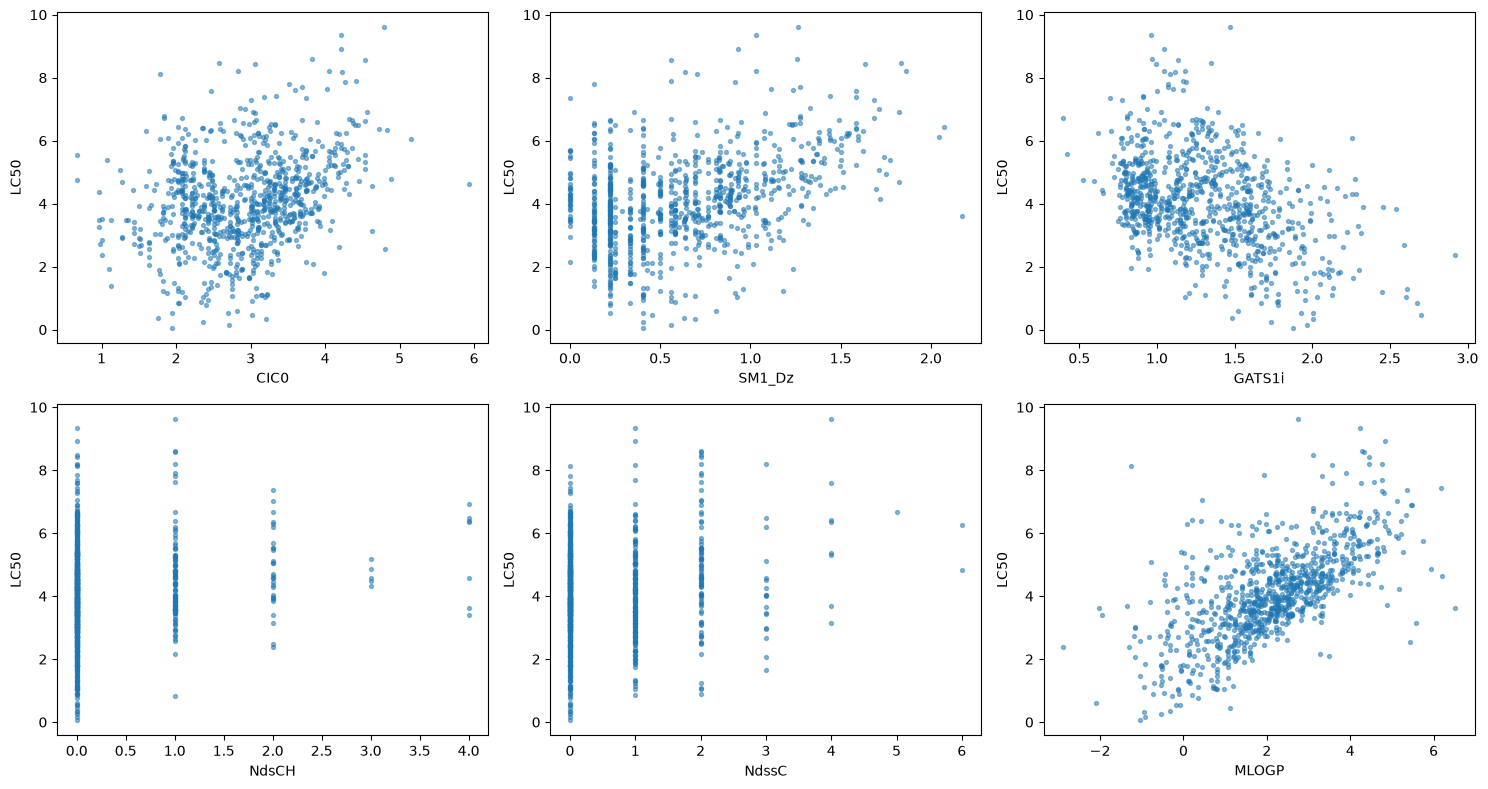

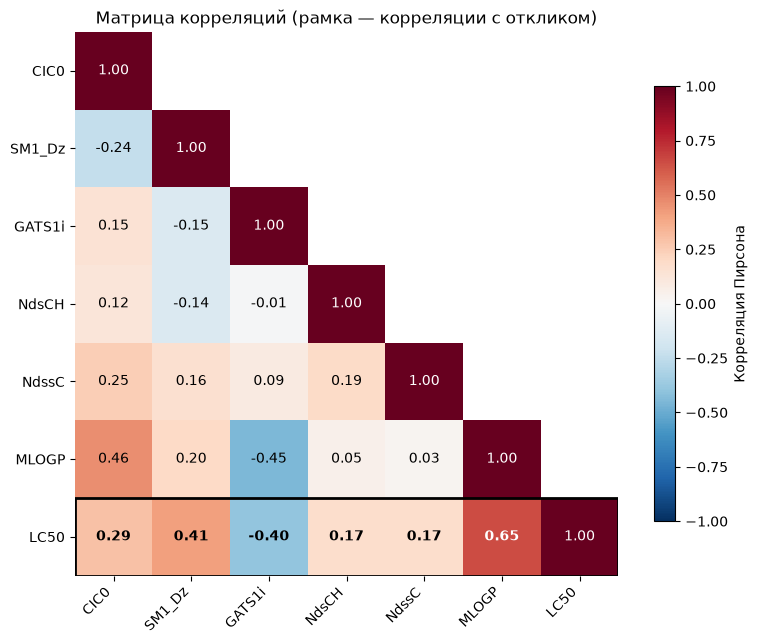

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), columns):
    ax.hist(df[col], bins=40, color='steelblue', alpha=0.8)
    ax.set_title(col)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), features):
    ax.scatter(df[col], df[target], s=8, alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel(target)
plt.tight_layout()
plt.show()

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # скрываем верхний треугольник
corr_masked = np.ma.array(corr.to_numpy(), mask=mask)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr_masked, cmap='RdBu_r', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, shrink=0.8, label='Корреляция Пирсона')

ax.set_xticks(range(len(columns)))
ax.set_yticks(range(len(columns)))
ax.set_xticklabels(columns, rotation=45, ha='right')
ax.set_yticklabels(columns)

for i in range(len(columns)):
    for j in range(i + 1):
        value = corr.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=10,
                color='white' if abs(value) > 0.5 else 'black',
                fontweight='bold' if columns[i] == target and i != j else 'normal')

ax.add_patch(plt.Rectangle((-0.5, len(columns) - 1.5), len(columns), 1,
                           fill=False, edgecolor='black', lw=2))   # рамка вокруг строки LC50
ax.set_title('Матрица корреляций (рамка — корреляции с откликом)')
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

Сильнее всего с откликом связан `MLOGP` (корреляция 0.65), затем `SM1_Dz` (0.41)
и `GATS1i` (−0.40). `NdsCH` и `NdssC` — счётчики атомов, в основном равные нулю
(у `NdsCH` 84% нулей). Распределение `LC50` имеет хвосты: есть очень токсичные и почти
нетоксичные соединения.

### 1. Классическая оценка: метод наименьших квадратов

Модель: $y_i = x_i^\top\beta + \varepsilon_i$, где $x_i$ - вектор признаков с единицей.

$$\hat\beta_{\text{OLS}} = \arg\min_\beta \sum_i (y_i - x_i^\top\beta)^2 = (X^\top X)^{-1}X^\top y.$$

Если ошибки нормальные и гомоскедастичные, то
$\hat\beta \sim N\big(\beta,\ \sigma^2 (X^\top X)^{-1}\big)$, и отсюда классические
$t$-тесты и доверительные интервалы $\hat\beta_j \pm t_{n-p,\,0.975}\,\hat\sigma\sqrt{[(X^\top X)^{-1}]_{jj}}$.

Квадратичная потеря делает МНК чувствительным к выбросам: точка с остатком $r$ вносит
в целевую функцию $r^2$, а её влияние на оценку неограниченно.

In [7]:
X = sm.add_constant(df[features]).to_numpy()
y = df[target].to_numpy()
names = ['const'] + features
n, p = X.shape

ols = sm.OLS(y, X).fit()
print(ols.summary(xname=names))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.577
Model:                            OLS   Adj. R-squared:                  0.574
Method:                 Least Squares   F-statistic:                     205.0
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          1.33e-164
Time:                        21:05:11   Log-Likelihood:                -1238.0
No. Observations:                 908   AIC:                             2490.
Df Residuals:                     901   BIC:                             2524.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.1746      0.181     12.000      0.0

**Результат МНК.** $R^2 = 0.577$; все признаки значимы, кроме `NdssC` ($p = 0.11$).
Тесты нормальности остатков (Omnibus, Jarque–Bera) отвергают гипотезу: эксцесс 6.0
при нормальных 3, асимметрия 0.47. Значит, у остатков тяжёлые хвосты, и классические
интервалы и тесты могут вводить в заблуждение.

### 2. Leverage и диагностика МНК

**Матрица-шляпа** $H = X(X^\top X)^{-1}X^\top$ переводит $y$ в прогноз: $\hat y = Hy$.
Диагональный элемент $h_{ii}$ (**leverage**, «рычаг») показывает, насколько наблюдение
$i$ влияет на собственный прогноз. Свойства: $0 \le h_{ii} \le 1$, $\sum_i h_{ii} = p$,
поэтому среднее равно $p/n$. Высоким считают $h_{ii} > 2p/n$.

Leverage зависит только от $x$: точка далеко от центра облака признаков «тянет»
гиперплоскость, как длинный рычаг.

Типы необычных наблюдений:
- **вертикальный выброс:** обычный $x$, необычный $y$;
- **хорошая точка рычага:** необычный $x$, но $y$ согласуется с моделью;
- **плохая точка рычага:** необычный $x$ и $y$ не согласуется с моделью. Самый опасный случай.

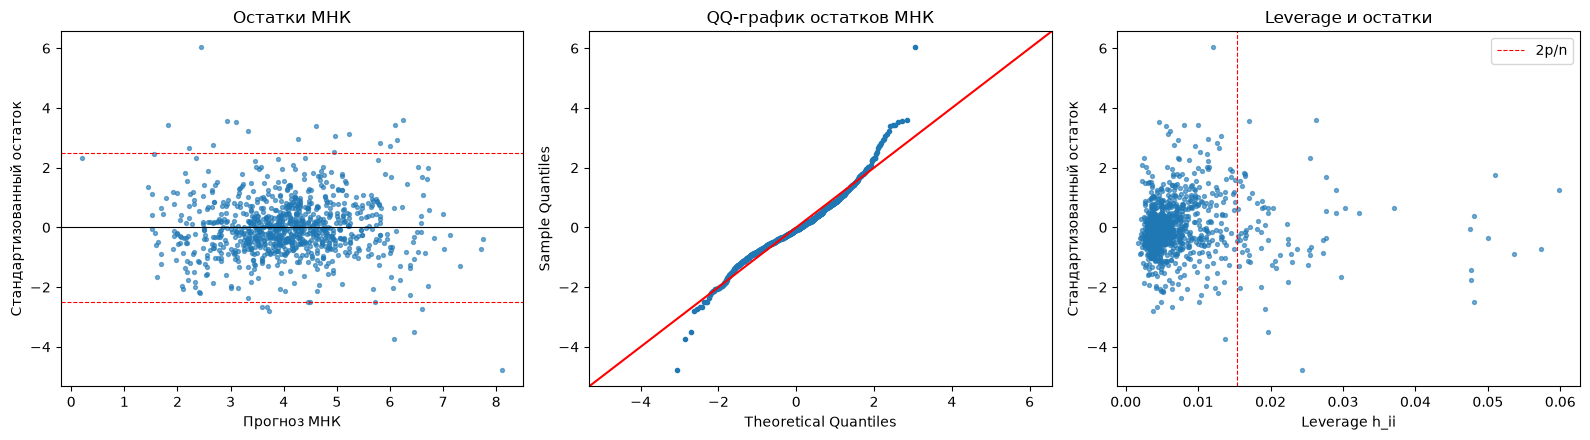

Точек с |остаток| > 2.5: 24
Точек с h_ii > 2p/n: 80


In [8]:
influence = ols.get_influence()
leverage = influence.hat_matrix_diag
std_resid = influence.resid_studentized_internal

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(ols.fittedvalues, std_resid, s=8, alpha=0.6)
axes[0].axhline(0, color='black', lw=0.8)
for level in [-2.5, 2.5]:
    axes[0].axhline(level, color='red', ls='--', lw=0.8)
axes[0].set(xlabel='Прогноз МНК', ylabel='Стандартизованный остаток', title='Остатки МНК')
sm.qqplot(std_resid, line='45', ax=axes[1], markersize=3)
axes[1].set_title('QQ-график остатков МНК')
axes[2].scatter(leverage, std_resid, s=8, alpha=0.6)
axes[2].axvline(2 * p / n, color='red', ls='--', lw=0.8, label='2p/n')
axes[2].set(xlabel='Leverage h_ii', ylabel='Стандартизованный остаток', title='Leverage и остатки')
axes[2].legend()
plt.tight_layout()
plt.show()

print('Точек с |остаток| > 2.5:', np.sum(np.abs(std_resid) > 2.5))
print('Точек с h_ii > 2p/n:', np.sum(leverage > 2 * p / n))

QQ-график показывает тяжёлые хвосты с обеих сторон. 24 точки имеют $|r| > 2.5$
(при нормальных ошибках ожидалось бы около 11), 80 точек — высокий leverage. Робастные методы здесь оправданы.

### 3. M-оценка для линейной регрессии

Квадрат заменяется функцией потерь $\rho$, которая растёт медленнее:

$$\hat\beta = \arg\min_\beta \sum_i \rho\!\left(\frac{y_i - x_i^\top\beta}{\hat\sigma}\right)
\quad\Longleftrightarrow\quad
\sum_i \psi\!\left(\frac{r_i}{\hat\sigma}\right) x_i = 0,\qquad \psi = \rho'.$$

Обозначим $w(u) = \psi(u)/u$. Тогда уравнение - это взвешенный МНК
$\sum_i w_i r_i x_i = 0$, и решение ищется методом **IRLS**
(iteratively reweighted least squares):

1. по текущему $\beta$ считаем остатки $r_i$ и масштаб $\hat\sigma$ (например, нормированный MAD);
2. считаем веса $w_i = w(r_i/\hat\sigma)$;
3. решаем взвешенный МНК и получаем новый $\beta$; повторяем до сходимости.

**Функция Губера** ($c = 1.345$, 95% эффективности при нормальных ошибках):
$\psi(u) = \operatorname{clip}(u, -c, c)$.

**Главная проблема M-оценки - leverage.** Ограничен только вклад остатка $\psi(r_i/\sigma)$,
но в уравнении он умножается на $x_i$. Если точка имеет огромный $x_i$, то вклад
$\psi\cdot x_i$ неограничен, и точка рычага может «перетянуть» оценку. Поэтому точка срыва
M-оценки с монотонной $\psi$ в регрессии равна $1/n$. Решения: **MM-оценки** (возвращающаяся
$\psi$ + робастный старт) и **GM-оценки** (отдельно ограничиваем вклад $x_i$).

In [9]:
def huber_psi(u, c=1.345):
    return np.clip(u, -c, c)

def huber_dpsi(u, c=1.345):
    return (np.abs(u) <= c).astype(float)

def huber_weight(u, c=1.345):
    return np.minimum(1, c / np.maximum(np.abs(u), 1e-12))

def bisquare_rho(u, c):
    # нормированная bisquare: 0 в нуле, 1 при |u| >= c
    t = np.minimum((u / c)**2, 1)
    return 1 - (1 - t)**3

def bisquare_weight(u, c):
    return np.maximum(1 - (u / c)**2, 0)**2

def bisquare_psi(u, c):
    return u * bisquare_weight(u, c)

def bisquare_dpsi(u, c):
    t = (u / c)**2
    return np.where(t < 1, (1 - t) * (1 - 5 * t), 0)

def weighted_ls(X, y, w):
    sw = np.sqrt(w)
    return np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)[0]

def mad_scale(r):
    return np.median(np.abs(r - np.median(r))) / norm.ppf(0.75)

In [10]:
def huber_regression(X, y, c=1.345, max_iter=500, tol=1e-10):
    beta = np.linalg.lstsq(X, y, rcond=None)[0]   # старт - МНК
    for iteration in range(max_iter):
        r = y - X @ beta
        s = mad_scale(r)
        w = huber_weight(r / s, c)
        beta_new = weighted_ls(X, y, w)
        if np.max(np.abs(beta_new - beta)) < tol:
            beta = beta_new
            break
        beta = beta_new
    return beta, mad_scale(y - X @ beta)

beta_huber, s_huber = huber_regression(X, y)
display(pd.DataFrame({'OLS': ols.params, 'Huber M': beta_huber}, index=names).round(4))

,OLS,Huber M
const,2.1746,1.9032
CIC0,0.3856,0.4017
SM1_Dz,1.2556,1.2767
GATS1i,-0.7464,-0.6593
NdsCH,0.4136,0.4334
NdssC,0.0643,0.0225
MLOGP,0.3901,0.4270


M-оценка Губера в целом согласуется с МНК: знаки и порядок величин всех коэффициентов
совпадают. Наибольшие изменения у `NdssC` (0.064 → 0.023, эффект почти исчезает),
`GATS1i` (−0.75 → −0.66) и `MLOGP` (0.39 → 0.43). Эти коэффициенты в МНК заметно смещены
наблюдениями с большими остатками. При этом оценка Губера ограничивает только влияние
остатков, но не leverage, поэтому дальше переходим к MM- и GM-оценкам.

### 4. MM-оценка

MM-оценка сочетает высокую точку срыва (50%) и высокую эффективность (95%).
Она строится в два шага.

**Шаг 1. S-оценка** - высокоустойчивая, но малоэффективная.
Для каждого $\beta$ определим M-оценку масштаба остатков $s(\beta)$ из уравнения
$$\frac1n\sum_i \rho_0\!\left(\frac{r_i(\beta)}{s}\right) = b,$$
где $\rho_0$ - bisquare с $c_0 = 1.5476$, $b = 0.5$. Такая калибровка даёт
состоятельность при нормальных ошибках и точку срыва $\min(b, 1-b) = 50\%$.
S-оценка: $\hat\beta_S = \arg\min_\beta s(\beta)$, то есть гиперплоскость с наименьшим
**робастным** разбросом остатков. Её эффективность при нормальных ошибках всего около 29%.

Целевая функция невыпуклая, поэтому используется алгоритм **fast-S**:
1. берём случайные подвыборки из $p$ точек и проводим через них точную гиперплоскость;
2. каждого кандидата улучшаем двумя шагами IRLS («concentration steps»);
3. лучших 10 кандидатов доводим до сходимости и выбираем минимум $s$.

Если хотя бы одна подвыборка не содержит выбросов, найдётся хороший кандидат.

**Шаг 2. M-оценка с фиксированным масштабом.** Фиксируем $\hat\sigma = s(\hat\beta_S)$
и решаем M-задачу с bisquare $\rho_1$, $c_1 = 4.685$ (эффективность 95%), стартуя из $\hat\beta_S$:
$$\hat\beta_{MM} = \arg\min_\beta \sum_i \rho_1\!\left(\frac{r_i(\beta)}{\hat\sigma}\right).$$
Bisquare возвращающаяся: точки с $|r|/\hat\sigma > 4.685$ получают вес 0, в том числе
точки рычага с большим остатком. Старт из S-оценки гарантирует, что IRLS придёт в «правильный»
локальный минимум, и точка срыва 50% сохраняется.

In [11]:
C_S = 1.5476   # для S-оценки: точка срыва 50%
B_S = 0.5
C_MM = 4.685   # для MM-шага: эффективность 95% при нормальных ошибках

def m_scale(r, c=C_S, b=B_S, max_iter=200, tol=1e-10):
    # решает mean(rho(r/s)) = b итерацией s <- s * sqrt(mean(rho(r/s)) / b)
    s = mad_scale(r)
    if s == 0:
        return 0.0
    for iteration in range(max_iter):
        s_new = s * np.sqrt(np.mean(bisquare_rho(r / s, c)) / b)
        if abs(s_new - s) < tol * s:
            return s_new
        s = s_new
    return s

def s_refine(X, y, beta, steps):
    for step in range(steps):
        r = y - X @ beta
        s = m_scale(r)
        w = bisquare_weight(r / s, C_S)
        beta_new = weighted_ls(X, y, w)
        if np.max(np.abs(beta_new - beta)) < 1e-10:
            beta = beta_new
            break
        beta = beta_new
    return beta, m_scale(y - X @ beta)

def s_regression(X, y, n_subsets=500, n_best=10, seed=0):
    rng = np.random.default_rng(seed)
    n, p = X.shape
    candidates = []
    for k in range(n_subsets):
        idx = rng.choice(n, p, replace=False)
        if np.linalg.matrix_rank(X[idx]) < p:
            continue
        beta = np.linalg.solve(X[idx], y[idx])
        candidates.append(s_refine(X, y, beta, steps=2))
    candidates.sort(key=lambda item: item[1])
    best_beta, best_s = None, np.inf
    for beta, s in candidates[:n_best]:
        beta, s = s_refine(X, y, beta, steps=200)
        if s < best_s:
            best_beta, best_s = beta, s
    return best_beta, best_s

def mm_regression(X, y, beta_start, scale, c=C_MM, max_iter=500, tol=1e-10):
    beta = beta_start.copy()
    for iteration in range(max_iter):
        w = bisquare_weight((y - X @ beta) / scale, c)
        beta_new = weighted_ls(X, y, w)
        if np.max(np.abs(beta_new - beta)) < tol:
            beta = beta_new
            break
        beta = beta_new
    return beta

In [12]:
beta_s, s_s = s_regression(X, y)
beta_mm = mm_regression(X, y, beta_s, s_s)
print(f'S-оценка масштаба: {s_s:.4f}   (МНК: {np.sqrt(ols.scale):.4f})')

S-оценка масштаба: 0.7208   (МНК: 0.9497)


Робастная оценка масштаба ошибок (0.72) на 32% меньше МНК-оценки (0.95).
МНК-оценка - корень из среднего квадрата остатков, и несколько больших остатков её раздувают.
S-оценка - M-оценка масштаба с ограниченной функцией bisquare (как в лабораторной 1),
она описывает разброс основной массы данных. Эта величина фиксируется на MM-шаге:
наблюдения с |r| > 4.685 · 0.72 ≈ 3.4 получают нулевой вес.

### 5. Обобщённые M-оценки (GM)

Идея GM-оценок - ограничить влияние точки **отдельно по остатку и по положению $x$**.
Вариант **Маллоуса**:
$$\sum_i w(x_i)\,\psi\!\left(\frac{r_i}{\hat\sigma}\right) x_i = 0.$$
Вариант Швеппе: $\sum_i w(x_i)\,\psi\!\left(\dfrac{r_i}{\hat\sigma\,w(x_i)}\right)x_i = 0$.

Вес $w(x_i)$ уменьшается для точек далеко от центра облака признаков.
Расстояние должно быть **робастным**, иначе группа точек рычага замаскирует себя.
Используем расстояние Махаланобиса с оценкой центра и ковариации **MCD**
(Minimum Covariance Determinant: ковариация по подвыборке из ~половины точек с минимальным
определителем):
$$d_i^2 = (x_i - \hat m)^\top \hat C^{-1}(x_i - \hat m),\qquad
w(x_i) = \min\!\left(1,\ \frac{\chi^2_{q,\,0.975}}{d_i^2}\right).$$

Для $\psi$ берём функцию Губера, масштаб - MAD остатков.

**Почему MCD только по непрерывным признакам.** У `NdsCH` 84% нулей. В MCD-подвыборке
этот признак оказывается тождественно нулевым, ковариационная матрица вырождается,
и минимальное собственное значение равно нулю (это проверяется в коде ниже). Поэтому
расстояния считаем по `CIC0`, `SM1_Dz`, `GATS1i`, `MLOGP`. Дискретные счётчики — стандартная
трудность GM-оценок.

**Ограничение GM:** их точка срыва убывает с ростом размерности (порядка $1/(p+1)$),
поэтому при многих признаках предпочтительнее MM-оценки.

In [13]:
continuous = ['CIC0', 'SM1_Dz', 'GATS1i', 'MLOGP']

mcd_all = MinCovDet(random_state=0).fit(df[features])
print('Мин. собственное число MCD по всем признакам:', np.linalg.eigvalsh(mcd_all.covariance_).min())

mcd = MinCovDet(random_state=0).fit(df[continuous])
robust_dist2 = mcd.mahalanobis(df[continuous])
cutoff = chi2.ppf(0.975, df=len(continuous))
weights_x = np.minimum(1, cutoff / robust_dist2)
print('Мин. собственное число MCD по непрерывным признакам:', np.linalg.eigvalsh(mcd.covariance_).min())
print('Точек с d² > χ²(0.975):', np.sum(robust_dist2 > cutoff))

Мин. собственное число MCD по всем признакам: 2.775557561562883e-17
Мин. собственное число MCD по непрерывным признакам: 0.038540864884616347
Точек с d² > χ²(0.975): 171


In [14]:
def gm_regression(X, y, weights_x, c=1.345, max_iter=500, tol=1e-10):
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    for iteration in range(max_iter):
        r = y - X @ beta
        s = mad_scale(r)
        w = weights_x * huber_weight(r / s, c)
        beta_new = weighted_ls(X, y, w)
        if np.max(np.abs(beta_new - beta)) < tol:
            beta = beta_new
            break
        beta = beta_new
    return beta, mad_scale(y - X @ beta)

beta_gm, s_gm = gm_regression(X, y, weights_x)

coef_table = pd.DataFrame({'OLS': ols.params, 'Huber M': beta_huber, 'S': beta_s,
                           'MM': beta_mm, 'GM (Mallows)': beta_gm}, index=names)
display(coef_table.round(4))
display(pd.Series({'OLS': np.sqrt(ols.scale), 'Huber M': s_huber, 'S / MM': s_s, 'GM': s_gm},
                  name='оценка σ').round(4))

,OLS,Huber M,S,MM,GM (Mallows)
const,2.1746,1.9032,1.1310,1.7961,1.8418
CIC0,0.3856,0.4017,0.6657,0.3955,0.4257
SM1_Dz,1.2556,1.2767,1.3673,1.2616,1.2879
GATS1i,-0.7464,-0.6593,-0.7713,-0.6116,-0.6888
NdsCH,0.4136,0.4334,0.3180,0.4332,0.4345
NdssC,0.0643,0.0225,-0.1548,0.0187,0.0073
MLOGP,0.3901,0.4270,0.4665,0.4556,0.4391


OLS        0.9497
Huber M    0.7236
S / MM     0.7208
GM         0.7355
Name: оценка σ, dtype: float64

**Сравнение оценок.**

- Huber M, MM и GM согласованы между собой и заметно отличаются от МНК:
  свободный член 2.17 → 1.80 (MM), `GATS1i` −0.75 → −0.61, `MLOGP` 0.39 → 0.46,
  `NdssC` 0.064 → 0.019.
- Оценка масштаба МНК (0.95) на 32% больше робастной (0.72): выбросы раздувают дисперсию.
- Сама S-оценка отличается сильнее (например, `NdssC` = −0.15): она робастна, но малоэффективна
  и шумна. Поэтому её используют только как старт и источник масштаба для MM.
- На этих данных Huber M близка к MM. Значит, «плохие» точки рычага здесь не настолько
  экстремальны, чтобы сломать монотонную M-оценку, но MM даёт гарантию точки срыва 50%.

### 6. Сравнение функций потерь

| | МНК | Губер | Bisquare |
|---|---|---|---|
| $\rho(u)$ | $u^2/2$ | $u^2/2$ при $\lvert u\rvert\le c$, иначе $c\lvert u\rvert - c^2/2$ | $\frac{c^2}{6}\big[1-(1-u^2/c^2)^3\big]$ при $\lvert u\rvert<c$, иначе $c^2/6$ |
| рост $\rho$ | квадратичный | линейный в хвостах | ограничена |
| $\psi = \rho'$ | неограничена | ограничена ($\pm c$) | возвращается к 0 |
| вес выброса | 1 | $c/\lvert u\rvert \to 0$ медленно | ровно 0 при $\lvert u\rvert\ge c$ |
| выпуклость | да | да, решение единственно | нет, нужен хороший старт |

**Разумность выбора** проверяем на данных: смотрим, где лежат стандартизованные остатки
относительно порогов $c$, какую долю потерь дают худшие точки и есть ли выигрыш
в прогнозе на кросс-валидации.

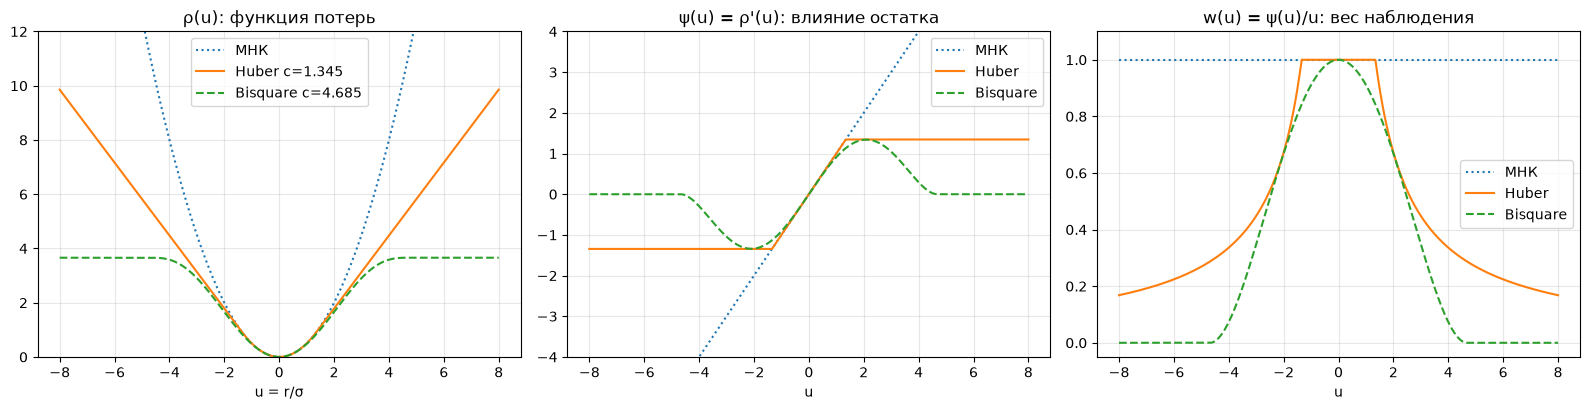

In [15]:
u = np.linspace(-8, 8, 801)
rho_ls = u**2 / 2
rho_huber = np.where(np.abs(u) <= 1.345, u**2 / 2, 1.345 * np.abs(u) - 1.345**2 / 2)
rho_bis = C_MM**2 / 6 * bisquare_rho(u, C_MM)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for curve, label, style in [(rho_ls, 'МНК', ':'), (rho_huber, 'Huber c=1.345', '-'),
                            (rho_bis, 'Bisquare c=4.685', '--')]:
    axes[0].plot(u, curve, style, label=label)
axes[0].set(ylim=(0, 12), title='ρ(u): функция потерь', xlabel='u = r/σ')
axes[1].plot(u, u, ':', label='МНК')
axes[1].plot(u, huber_psi(u), '-', label='Huber')
axes[1].plot(u, bisquare_psi(u, C_MM), '--', label='Bisquare')
axes[1].set(ylim=(-4, 4), title="ψ(u) = ρ'(u): влияние остатка", xlabel='u')
axes[2].plot(u, np.ones_like(u), ':', label='МНК')
axes[2].plot(u, huber_weight(u), '-', label='Huber')
axes[2].plot(u, bisquare_weight(u, C_MM), '--', label='Bisquare')
axes[2].set(ylim=(-0.05, 1.1), title='w(u) = ψ(u)/u: вес наблюдения', xlabel='u')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,зона,остатки МНК,остатки MM
0,|u| ≤ 1.345,0.8623,0.7830
1,1.345 < |u| ≤ 4.685,0.1355,0.2081
2,|u| > 4.685,0.0022,0.0088


Доля суммарных потерь от 10 худших точек: МНК 0.174, Huber 0.112
MM: наблюдений с весом 0: 8 , с весом < 0.5: 56


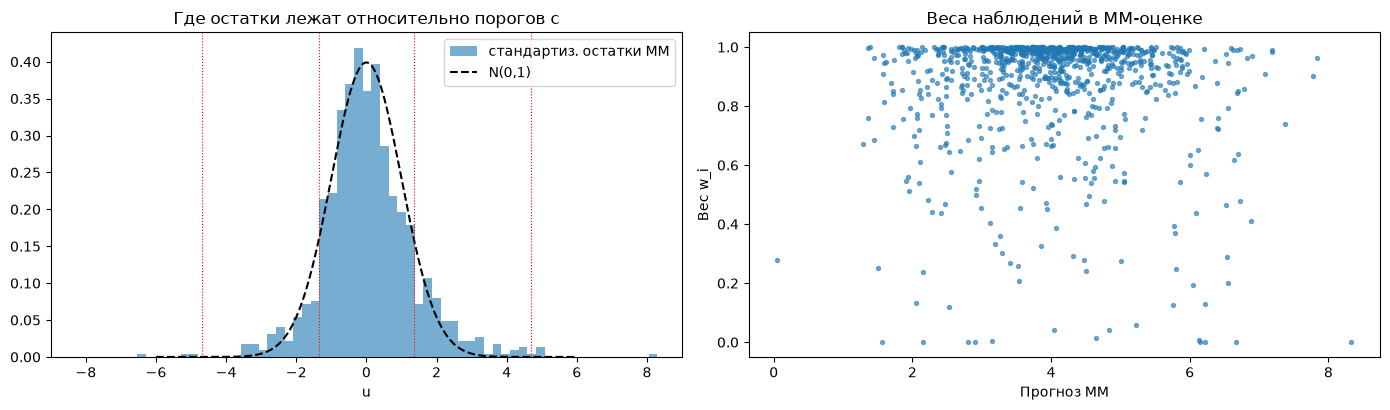

In [16]:
u_ols = (y - X @ ols.params) / np.sqrt(ols.scale)
u_mm = (y - X @ beta_mm) / s_s
w_mm = bisquare_weight(u_mm, C_MM)

zones = pd.DataFrame({
    'зона': ['|u| ≤ 1.345', '1.345 < |u| ≤ 4.685', '|u| > 4.685'],
    'остатки МНК': [np.mean(np.abs(u_ols) <= 1.345),
                    np.mean((np.abs(u_ols) > 1.345) & (np.abs(u_ols) <= C_MM)),
                    np.mean(np.abs(u_ols) > C_MM)],
    'остатки MM': [np.mean(np.abs(u_mm) <= 1.345),
                   np.mean((np.abs(u_mm) > 1.345) & (np.abs(u_mm) <= C_MM)),
                   np.mean(np.abs(u_mm) > C_MM)],
})
display(zones.round(4))

loss_ols = u_ols**2 / 2
loss_huber = np.where(np.abs(u_ols) <= 1.345, u_ols**2 / 2, 1.345 * np.abs(u_ols) - 1.345**2 / 2)
worst = np.argsort(-np.abs(u_ols))[:10]
print(f'Доля суммарных потерь от 10 худших точек: МНК {loss_ols[worst].sum() / loss_ols.sum():.3f}, '
      f'Huber {loss_huber[worst].sum() / loss_huber.sum():.3f}')
print('MM: наблюдений с весом 0:', np.sum(w_mm == 0), ', с весом < 0.5:', np.sum(w_mm < 0.5))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].hist(u_mm, bins=60, density=True, alpha=0.6, label='стандартиз. остатки MM')
grid = np.linspace(-6, 6, 400)
axes[0].plot(grid, norm.pdf(grid), 'k--', label='N(0,1)')
for c in [1.345, C_MM]:
    for sign in [-1, 1]:
        axes[0].axvline(sign * c, color='red', lw=0.8, ls=':')
axes[0].set(xlim=(-9, 9), title='Где остатки лежат относительно порогов c', xlabel='u')
axes[0].legend()
axes[1].scatter(X @ beta_mm, w_mm, s=8, alpha=0.6)
axes[1].set(xlabel='Прогноз MM', ylabel='Вес w_i', title='Веса наблюдений в MM-оценке')
plt.tight_layout()
plt.show()

In [17]:
def fit_predict(method, X_train, y_train, X_test):
    if method == 'OLS':
        beta = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
    elif method == 'Huber M':
        beta, _ = huber_regression(X_train, y_train)
    elif method == 'MM':
        beta0, scale0 = s_regression(X_train, y_train, n_subsets=200)
        beta = mm_regression(X_train, y_train, beta0, scale0)
    else:
        cont_idx = [names.index(v) for v in continuous]
        mcd_train = MinCovDet(random_state=0).fit(X_train[:, cont_idx])
        wx = np.minimum(1, cutoff / mcd_train.mahalanobis(X_train[:, cont_idx]))
        beta, _ = gm_regression(X_train, y_train, wx)
    return X_test @ beta

def trimmed_rmse(e, alpha=0.1):
    a = np.sort(np.abs(e))
    return np.sqrt(np.mean(a[:int((1 - alpha) * len(a))]**2))

methods = ['OLS', 'Huber M', 'MM', 'GM']
cv_errors = {m: np.zeros(n) for m in methods}
for train, test in KFold(5, shuffle=True, random_state=0).split(X):
    for m in methods:
        cv_errors[m][test] = y[test] - fit_predict(m, X[train], y[train], X[test])

cv_table = pd.DataFrame({m: {'RMSE': np.sqrt(np.mean(e**2)), 'MAE': np.mean(np.abs(e)),
                             'MedAE': np.median(np.abs(e)), 'RMSE по 90% лучших': trimmed_rmse(e)}
                         for m, e in cv_errors.items()}).T
display(cv_table.round(4))

,RMSE,MAE,MedAE,RMSE по 90% лучших
OLS,0.9615,0.7009,0.5270,0.6542
Huber M,0.9612,0.6950,0.5075,0.6487
MM,0.9632,0.6950,0.5133,0.6477
GM,0.9636,0.6945,0.5058,0.6480


**Вывод о функциях потерь.**

- По остаткам MM 78% точек в зоне $|u|\le1.345$, где все три функции совпадают
  с квадратичной. Различия касаются только хвостов.
- 8 точек (0.9%) лежат за $|u| > 4.685$ и получают в MM вес 0. При нормальных ошибках
  ожидалось бы около 0.0003% таких точек, так что это действительно выбросы.
- В МНК 10 худших точек (1.1% данных) дают 17.4% всей целевой функции, у Губера - 11.2%.
  Квадратичная потеря позволяет нескольким точкам диктовать решение.
- На 5-кратной кросс-валидации RMSE у всех методов почти одинаковая (~0.96): сама RMSE
  определяется выбросами в тестовых фолдах, которые не предсказывает ни одна модель.
  По робастным метрикам (MAE, медиана ошибки, RMSE по 90% лучших) робастные методы немного
  лучше (MedAE 0.527 у МНК против 0.506–0.513).

Итог: ограниченная потеря разумна для этих данных. Основной выигрыш не в прогнозе,
а в устойчивых коэффициентах и корректных выводах о них.

### 7. Робастные доверительные интервалы и тесты

Для M- и MM-оценок с фиксированным масштабом при больших $n$
$$\sqrt n(\hat\beta - \beta) \xrightarrow{d} N\big(0,\ \sigma^2 A^{-1}BA^{-1}\big),\quad
A = E\big[\psi'(u)\,xx^\top\big],\quad B = E\big[\psi(u)^2\,xx^\top\big].$$
Подставляя выборочные средние, получаем **сэндвич-оценку** ковариации
$$\widehat{\operatorname{Cov}}(\hat\beta) = \frac{\hat\sigma^2}{n}\hat A^{-1}\hat B\hat A^{-1}.$$
Для GM-оценки в $A$ и $B$ добавляются веса $w(x_i)$.

Сэндвич не предполагает нормальность и одинаковую дисперсию ошибок, поэтому
устойчив и к гетероскедастичности.

- **Доверительный интервал:** $\hat\beta_j \pm z_{0.975}\,\widehat{SE}_j$.
- **Робастный тест Вальда** для $H_0: R\beta = 0$ ($q$ ограничений):
  $W = (R\hat\beta)^\top\big(R\,\widehat{\operatorname{Cov}}\,R^\top\big)^{-1}(R\hat\beta)\ \sim\ \chi^2_q$.

In [18]:
def sandwich_cov(X, r, scale, psi, dpsi, weights_x=None):
    u = r / scale
    a = dpsi(u)
    b = psi(u)
    if weights_x is not None:
        a = a * weights_x
        b = b * weights_x
    n = len(r)
    A = (X * a[:, None]).T @ X / n
    B = (X * (b**2)[:, None]).T @ X / n
    A_inv = np.linalg.inv(A)
    return scale**2 * A_inv @ B @ A_inv / n

def inference_table(beta, cov, names, level=0.95):
    se = np.sqrt(np.diag(cov))
    z = beta / se
    q = norm.ppf(0.5 + level / 2)
    return pd.DataFrame({'coef': beta, 'SE': se, 'z': z, 'p-value': 2 * norm.sf(np.abs(z)),
                         'CI low': beta - q * se, 'CI high': beta + q * se}, index=names)

cov_mm = sandwich_cov(X, y - X @ beta_mm, s_s,
                      lambda t: bisquare_psi(t, C_MM), lambda t: bisquare_dpsi(t, C_MM))
mm_inf = inference_table(beta_mm, cov_mm, names)
print('MM-оценка:')
display(mm_inf.round(4))

cov_gm = sandwich_cov(X, y - X @ beta_gm, s_gm, huber_psi, huber_dpsi, weights_x)
print('GM-оценка:')
display(inference_table(beta_gm, cov_gm, names).round(4))

MM-оценка:


,coef,SE,z,p-value,CI low,CI high
const,1.7961,0.1878,9.5642,0.0000,1.4280,2.1642
CIC0,0.3955,0.0680,5.8141,0.0000,0.2622,0.5288
SM1_Dz,1.2616,0.0949,13.2922,0.0000,1.0756,1.4476
GATS1i,-0.6116,0.0927,-6.6002,0.0000,-0.7932,-0.4300
NdsCH,0.4332,0.0666,6.5033,0.0000,0.3027,0.5638
NdssC,0.0187,0.0511,0.3664,0.7141,-0.0815,0.1189
MLOGP,0.4556,0.0365,12.4651,0.0000,0.3840,0.5272


GM-оценка:


,coef,SE,z,p-value,CI low,CI high
const,1.8418,0.1832,10.0550,0.0000,1.4828,2.2008
CIC0,0.4257,0.0718,5.9318,0.0000,0.2851,0.5664
SM1_Dz,1.2879,0.0972,13.2446,0.0000,1.0973,1.4785
GATS1i,-0.6888,0.0962,-7.1625,0.0000,-0.8773,-0.5003
NdsCH,0.4345,0.0601,7.2260,0.0000,0.3166,0.5523
NdssC,0.0073,0.0446,0.1626,0.8708,-0.0802,0.0947
MLOGP,0.4391,0.0380,11.5419,0.0000,0.3646,0.5137


In [19]:
ols_ci = ols.conf_int()
ci_compare = pd.DataFrame({
    'OLS: CI': [f'[{a:.3f}, {b:.3f}]' for a, b in ols_ci],
    'OLS: p': ols.pvalues,
    'MM: CI': [f'[{a:.3f}, {b:.3f}]' for a, b in zip(mm_inf['CI low'], mm_inf['CI high'])],
    'MM: p': mm_inf['p-value'],
}, index=names)
display(ci_compare.round(4))

def wald_test(beta, cov, idx):
    R = np.zeros((len(idx), len(beta)))
    R[np.arange(len(idx)), idx] = 1
    rb = R @ beta
    stat = rb @ np.linalg.solve(R @ cov @ R.T, rb)
    return stat, chi2.sf(stat, len(idx))

stat, pval = wald_test(beta_mm, cov_mm, [names.index('NdssC')])
print(f'H0: β(NdssC) = 0.  Робастный Wald: W = {stat:.3f}, p = {pval:.4f}')
print('Классический F-тест:', ols.f_test(np.eye(p)[[names.index('NdssC')]]))

stat, pval = wald_test(beta_mm, cov_mm, list(range(1, p)))
print(f'H0: все коэффициенты при признаках = 0.  Робастный Wald: W = {stat:.1f}, p = {pval:.2e}')

,OLS: CI,OLS: p,MM: CI,MM: p
const,"[1.819, 2.530]",0.0000,"[1.428, 2.164]",0.0000
CIC0,"[0.266, 0.505]",0.0000,"[0.262, 0.529]",0.0000
SM1_Dz,"[1.085, 1.426]",0.0000,"[1.076, 1.448]",0.0000
GATS1i,"[-0.945, -0.548]",0.0000,"[-0.793, -0.430]",0.0000
NdsCH,"[0.307, 0.520]",0.0000,"[0.303, 0.564]",0.0000
NdssC,"[-0.015, 0.144]",0.1138,"[-0.081, 0.119]",0.7141
MLOGP,"[0.324, 0.456]",0.0000,"[0.384, 0.527]",0.0000


H0: β(NdssC) = 0.  Робастный Wald: W = 0.134, p = 0.7141
Классический F-тест: <F test: F=2.5061505680200034, p=0.11375356116635134, df_denom=901, df_num=1>
H0: все коэффициенты при признаках = 0.  Робастный Wald: W = 1003.6, p = 1.51e-213


**Выводы по интервалам и тестам**
- Интервал для `MLOGP` сдвинулся: [0.324, 0.456] у МНК против [0.384, 0.527] у MM.
  МНК занижает эффект липофильности. Для `GATS1i` наоборот: [−0.945, −0.548] против [−0.793, −0.430].
- Для `NdssC` у МНК $p = 0.11$ («почти значим»), а робастный тест Вальда даёт $p = 0.71$:
  эффекта нет, а «намёк» на него в МНК создавали выбросы.
- Модель в целом значима: $W = 1003.6$, $p \approx 10^{-213}$.

### 8. Природа выбросов

**Диагностический график Руссеу–ван Зомерена:** по горизонтали - робастное расстояние
$d_i$ (MCD), по вертикали - стандартизованный остаток MM. Пороги: $\sqrt{\chi^2_{q,0.975}}$
и $\pm2.5$. Четыре зоны соответствуют четырём типам наблюдений из раздела 2.

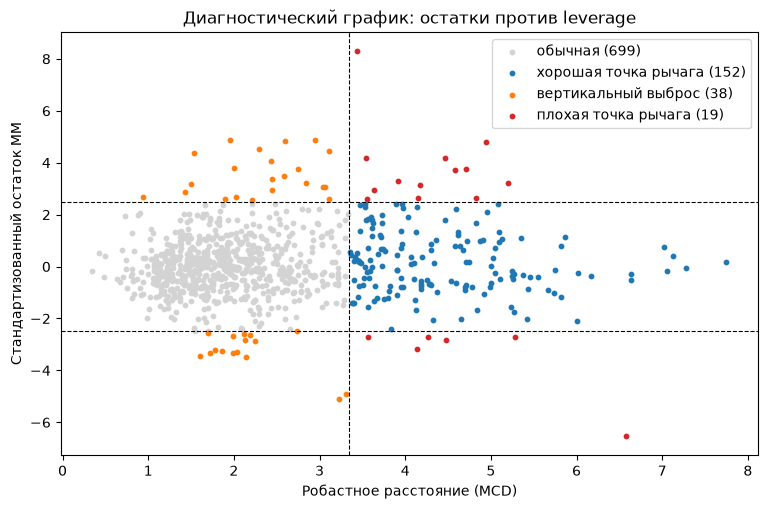

type
обычная                 699
хорошая точка рычага    152
вертикальный выброс      38
плохая точка рычага      19
Name: count, dtype: int64

In [20]:
diag = df.copy()
diag['robust_dist'] = np.sqrt(robust_dist2)
diag['robust_resid'] = u_mm
diag['weight_MM'] = w_mm
dist_cut = np.sqrt(cutoff)
diag['type'] = np.select(
    [(np.abs(u_mm) > 2.5) & (diag['robust_dist'] > dist_cut),
     np.abs(u_mm) > 2.5,
     diag['robust_dist'] > dist_cut],
    ['плохая точка рычага', 'вертикальный выброс', 'хорошая точка рычага'], default='обычная')

colors = {'обычная': 'lightgray', 'хорошая точка рычага': 'tab:blue',
          'вертикальный выброс': 'tab:orange', 'плохая точка рычага': 'tab:red'}
plt.figure(figsize=(9, 5.5))
for kind, color in colors.items():
    part = diag[diag['type'] == kind]
    plt.scatter(part['robust_dist'], part['robust_resid'], s=10, color=color, label=f'{kind} ({len(part)})')
plt.axhline(2.5, color='black', ls='--', lw=0.8)
plt.axhline(-2.5, color='black', ls='--', lw=0.8)
plt.axvline(dist_cut, color='black', ls='--', lw=0.8)
plt.xlabel('Робастное расстояние (MCD)')
plt.ylabel('Стандартизованный остаток MM')
plt.title('Диагностический график: остатки против leverage')
plt.legend()
plt.show()

display(diag['type'].value_counts())

In [21]:
display(diag.sort_values('weight_MM').head(10).round(3))

is_outlier = diag['type'].isin(['вертикальный выброс', 'плохая точка рычага'])
display(pd.DataFrame({'выбросы (медиана)': diag.loc[is_outlier, columns].median(),
                      'остальные (медиана)': diag.loc[~is_outlier, columns].median()}).round(3))
print('Выбросов с положительным остатком (токсичнее прогноза):',
      np.sum(diag.loc[is_outlier, 'robust_resid'] > 0), 'из', is_outlier.sum())

,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50,robust_dist,robust_resid,weight_MM,type
447,1.786,0.702,1.081,0,0,-1.265,8.132,3.438,8.299,0.000,плохая точка рычага
65,1.594,0.223,1.333,2,0,0.094,6.297,2.599,4.849,0.000,вертикальный выброс
120,1.251,0.251,1.126,0,0,-0.786,5.072,2.943,4.871,0.000,вертикальный выброс
372,3.465,2.171,0.888,0,0,6.515,3.623,6.583,-6.531,0.000,плохая точка рычага
259,4.785,1.263,1.471,1,4,2.749,9.612,4.937,4.813,0.000,плохая точка рычага
237,2.031,0.872,1.475,0,1,0.202,6.424,1.951,4.878,0.000,вертикальный выброс
169,4.630,0.405,1.458,2,1,5.579,3.139,3.305,-4.904,0.000,вертикальный выброс
182,4.810,0.693,1.420,0,2,5.426,2.548,3.232,-5.086,0.000,вертикальный выброс
219,2.359,0.405,0.814,0,0,0.893,6.400,2.299,4.510,0.005,вертикальный выброс
680,4.219,1.033,0.963,0,1,4.246,9.354,3.110,4.470,0.008,вертикальный выброс


,выбросы (медиана),остальные (медиана)
CIC0,3.057,2.918
SM1_Dz,0.693,0.560
GATS1i,1.248,1.237
NdsCH,0.000,0.000
NdssC,1.000,0.000
MLOGP,1.936,2.129
LC50,5.072,3.959


Выбросов с положительным остатком (токсичнее прогноза): 35 из 57


**Что за выбросы.** Получилось 699 обычных точек, 152 хорошие точки рычага,
38 вертикальных выбросов и 19 плохих точек рычага.

- 35 из 57 выбросов имеют **положительный** остаток: вещество токсичнее, чем предсказывает
  модель. Медианная `LC50` у выбросов 5.07 против 3.96 у остальных.
- Возможная химическая интерпретация (гипотеза: в датасете нет названий веществ, проверить
  её напрямую нельзя). Дескрипторы, особенно logP, хорошо описывают **базовую (наркотическую)**
  токсичность, при которой вещество неспецифически растворяется в мембранах. Вещества
  со **специфическим механизмом** (реакционноспособные, пестициды, ингибиторы ферментов)
  токсичнее, чем «положено» по липофильности, и дают положительные выбросы.
  Отрицательные выбросы могут объясняться ограниченной растворимостью в воде или ошибками
  измерения.
- Значит, выбросы здесь не «мусор», а другой механизм действия. Робастная модель описывает
  основную массу веществ (базовую токсичность) и явно выделяет те, что ей не подчиняются.

### 9. Эксперимент: устойчивость к плохим точкам рычага

На исходных данных M-оценка Губера близка к MM: выбросы в основном вертикальные.
Чтобы проверить главное теоретическое отличие (устойчивость к leverage), искусственно
загрязним данные: у доли $\varepsilon$ молекул заменим `MLOGP` на значения около 9
(далеко за пределами данных) и поставим низкую токсичность `LC50` ≈ 1.
Это классические **плохие точки рычага**. Смотрим, как меняется коэффициент при `MLOGP`.

,доля загрязнения,OLS,Huber M,MM,GM
0,0.00,0.390,0.427,0.456,0.439
1,0.02,0.004,0.170,0.463,0.422
2,0.05,-0.189,-0.127,0.448,0.357
3,0.10,-0.277,-0.270,0.451,0.261
4,0.15,-0.313,-0.307,0.433,0.039


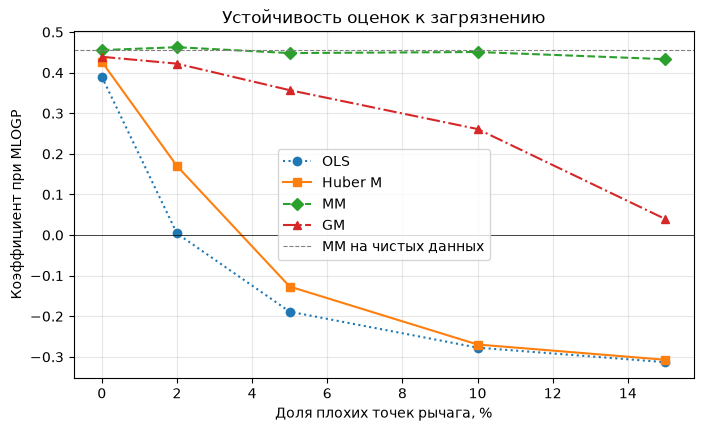

In [22]:
rng = np.random.default_rng(42)
j = names.index('MLOGP')
cont_idx = [names.index(v) for v in continuous]
fractions = [0, 0.02, 0.05, 0.10, 0.15]
rows = []

for frac in fractions:
    Xc, yc = X.copy(), y.copy()
    m = int(frac * n)
    if m > 0:
        idx = rng.choice(n, m, replace=False)
        Xc[idx, j] = rng.normal(9, 0.3, m)    # далёкий x: высокий leverage
        yc[idx] = rng.normal(1, 0.3, m)       # y не согласуется с моделью

    b_ols = np.linalg.lstsq(Xc, yc, rcond=None)[0]
    b_huber, _ = huber_regression(Xc, yc)
    b0, s0 = s_regression(Xc, yc)
    b_mm = mm_regression(Xc, yc, b0, s0)
    mcd_c = MinCovDet(random_state=0).fit(Xc[:, cont_idx])
    wx = np.minimum(1, cutoff / mcd_c.mahalanobis(Xc[:, cont_idx]))
    b_gm, _ = gm_regression(Xc, yc, wx)

    rows.append([frac, b_ols[j], b_huber[j], b_mm[j], b_gm[j]])

contamination = pd.DataFrame(rows, columns=['доля загрязнения', 'OLS', 'Huber M', 'MM', 'GM'])
display(contamination.round(3))

plt.figure(figsize=(8, 4.5))
for col, style in [('OLS', 'o:'), ('Huber M', 's-'), ('MM', 'D--'), ('GM', '^-.')]:
    plt.plot(contamination['доля загрязнения'] * 100, contamination[col], style, label=col)
plt.axhline(beta_mm[j], color='gray', lw=0.8, ls='--', label='MM на чистых данных')
plt.axhline(0, color='black', lw=0.5)
plt.xlabel('Доля плохих точек рычага, %')
plt.ylabel('Коэффициент при MLOGP')
plt.title('Устойчивость оценок к загрязнению')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Результат.** МНК ломается уже при 2% загрязнения: коэффициент при `MLOGP` падает
с 0.39 до 0. M-оценка Губера ломается при 5%: знак меняется, потому что монотонная $\psi$
ограничивает остаток, но не leverage. GM-оценка деградирует постепенно (при 15% эффект
почти исчезает): её точка срыва убывает с размерностью. MM-оценка остаётся около 0.45
при всех долях до 15%, что соответствует теоретической точке срыва 50%.

Вывод: на исходных данных разница между M и MM мала, но гарантию устойчивости
к точкам рычага даёт только MM.